loading the frameworks

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

loading the dataset

In [13]:
path = "../datasets/raw_users_dataset.csv"
df = pd.read_csv(path, index_col = "RowNumber")
df.head()

,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,,
1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [14]:
# first observation
df["CustomerId"].nunique(), df.shape[0]

(10000, 10000)

<p>since the CustomerID is all unique, has no predictive value and can result in the possiblity of overfitting, we can choose to remove it and we can choose to keep the RowNumber as the index columns </p>

In [ ]:
df.drop(["CustomerId"], inplace = True, axis=1)
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,
1,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


basic EDA

In [16]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


some of the numerical features require scaling

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Surname          10000 non-null  object 
 1   CreditScore      10000 non-null  int64  
 2   Geography        10000 non-null  object 
 3   Gender           10000 non-null  object 
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  int64  
 8   HasCrCard        10000 non-null  int64  
 9   IsActiveMember   10000 non-null  int64  
 10  EstimatedSalary  10000 non-null  float64
 11  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(3)
memory usage: 1015.6+ KB


observation: there are no missing values in any of the dataset, so no need for imputer

In [18]:
df.isnull().sum()

Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

no duplicate values

In [19]:
df.duplicated().sum()

np.int64(0)

surnames repeating, some are frequent and some are not... so suspecting surname correlation

In [20]:
df["Surname"].value_counts()

Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Hull          1
Sturdee       1
Flannagan     1
Dwyer         1
Corby         1
Name: count, Length: 2932, dtype: int64

In [24]:
df[df["Exited"] == 1]["Surname"].value_counts(), df[df["Exited"] == 0]["Surname"].value_counts()

(Surname
 Smith         9
 Martin        9
 McGregor      9
 Lin           9
 Shih          7
              ..
 Golubov       1
 Williamson    1
 Chikelu       1
 Caffyn        1
 Olson         1
 Name: count, Length: 1188, dtype: int64,
 Surname
 Scott       26
 Walker      24
 Smith       23
 Yeh         22
 Brown       21
             ..
 Muldrow      1
 Goforth      1
 Bearce       1
 Aldridge     1
 Sturdee      1
 Name: count, Length: 2616, dtype: int64)

a lot of people with common surnames have not exited and continued with the organization - so will not remove surname as it holds some value for prediction

Plotting

In [25]:
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
RowNumber,,,,,,,,,,,,
1,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
2,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
3,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
4,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
5,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


<Axes: xlabel='CreditScore', ylabel='Density'>

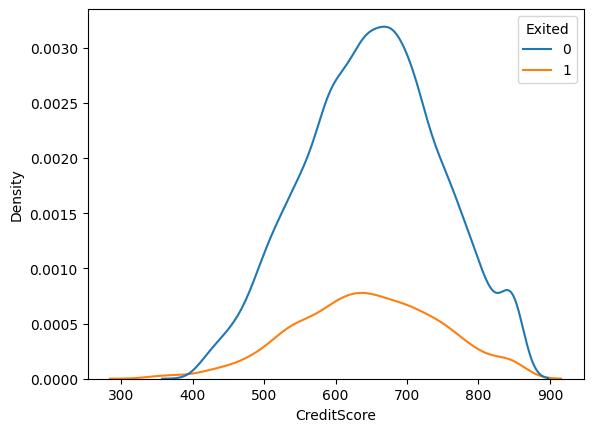

In [71]:
sns.kdeplot(data = df, x =  "CreditScore", hue = "Exited")

(array([  19.,  166.,  447.,  958., 1444., 1866., 1952., 1525.,  968.,
         655.]),
 array([350., 400., 450., 500., 550., 600., 650., 700., 750., 800., 850.]),
 <BarContainer object of 10 artists>)

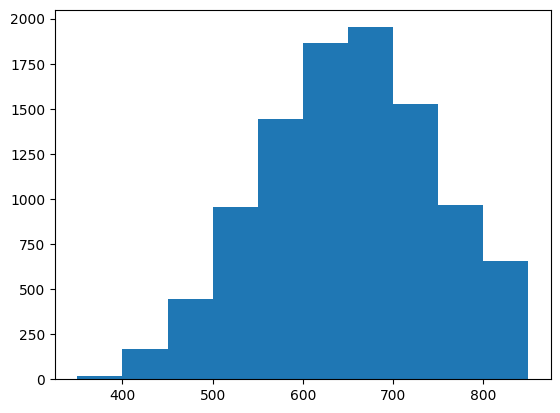

In [51]:
plt.hist("CreditScore", data = df)

np.float64(-0.07160660820092675)

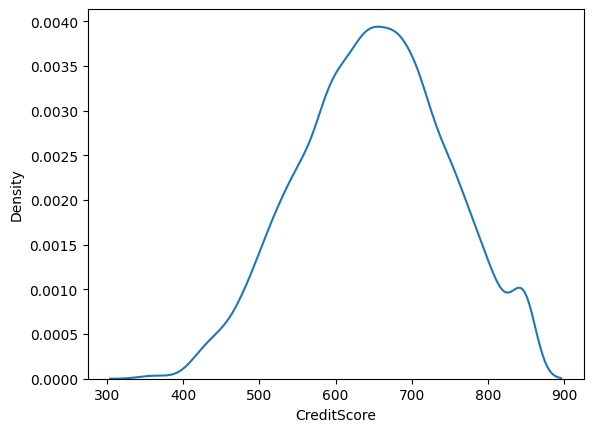

In [50]:
sns.kdeplot(x = "CreditScore", data = df)
df["CreditScore"].skew() # very much normal

almost normal curve

only three countries with almost 2:1:1 ratio split

<Axes: xlabel='Geography', ylabel='count'>

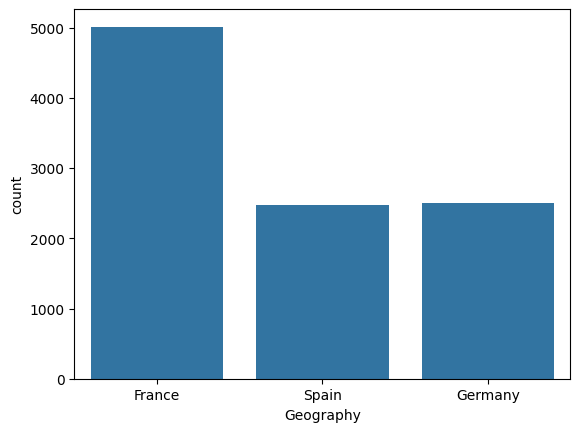

In [75]:
sns.countplot(data = df, x = "Geography")

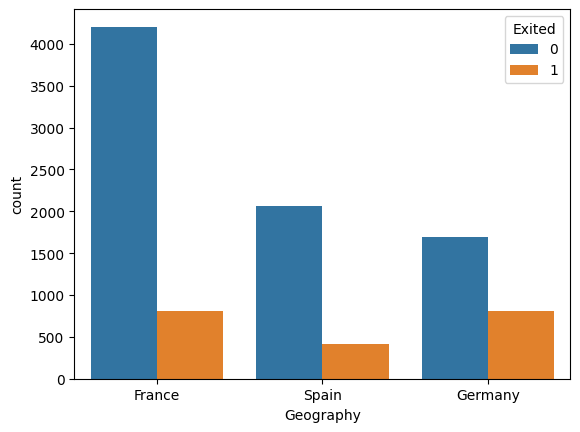

In [68]:
sns.countplot(data=df, x='Geography', hue='Exited')
plt.show()

<Axes: xlabel='Gender', ylabel='count'>

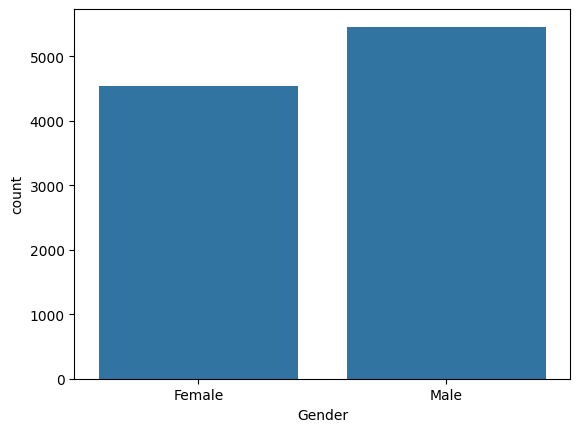

In [74]:
sns.countplot(data = df, x=  "Gender")

<Axes: xlabel='Gender', ylabel='count'>

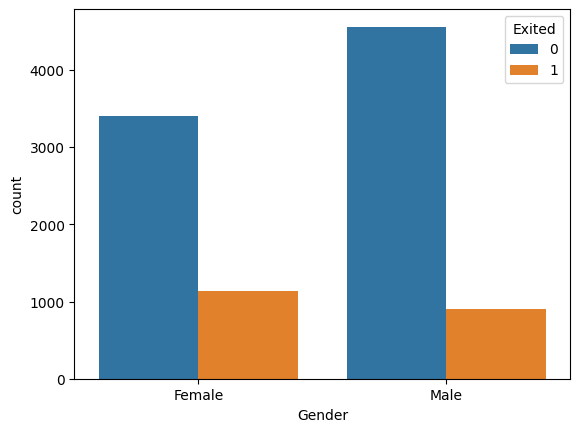

In [72]:
sns.countplot(data = df, x=  "Gender", hue = "Exited")

np.float64(1.0113202630234552)

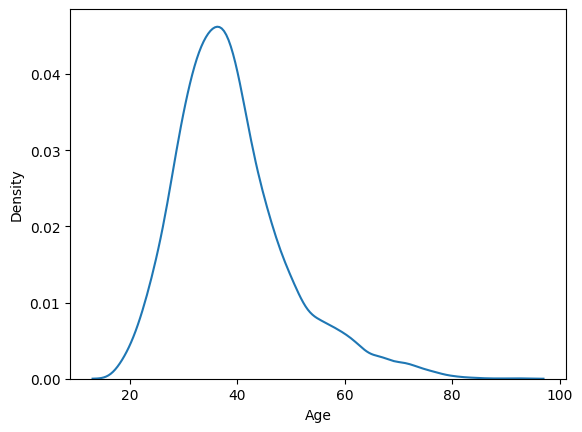

In [79]:
sns.kdeplot(data = df, x = "Age")
df["Age"].skew() # scaling must be done

<Axes: xlabel='Age', ylabel='Density'>

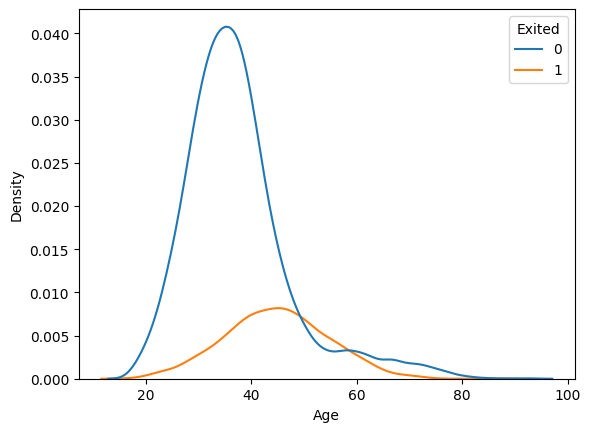

In [76]:
sns.kdeplot(data = df, x = "Age", hue = "Exited")

<Axes: xlabel='Tenure', ylabel='count'>

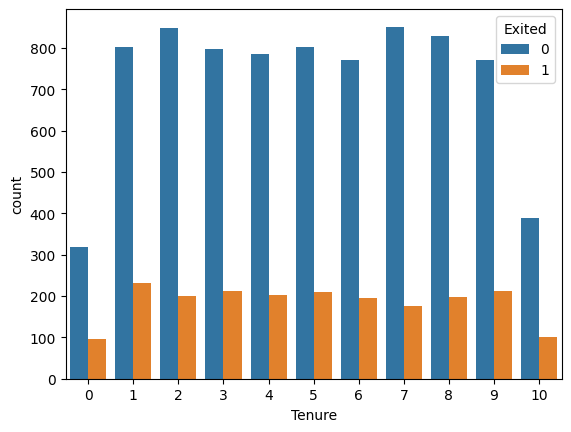

In [83]:
sns.countplot(data = df, x = "Tenure", hue = "Exited")

In [93]:
data = df["EstimatedSalary"]/ 10000

<Axes: xlabel='EstimatedSalary', ylabel='Density'>

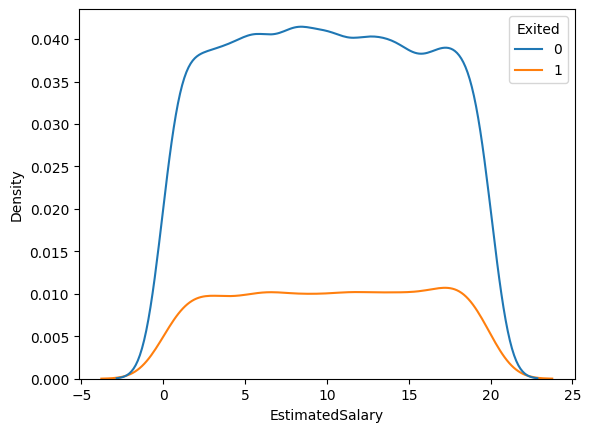

In [94]:
sns.kdeplot(x = data, hue = df["Exited"])

<Axes: xlabel='Balance', ylabel='Density'>

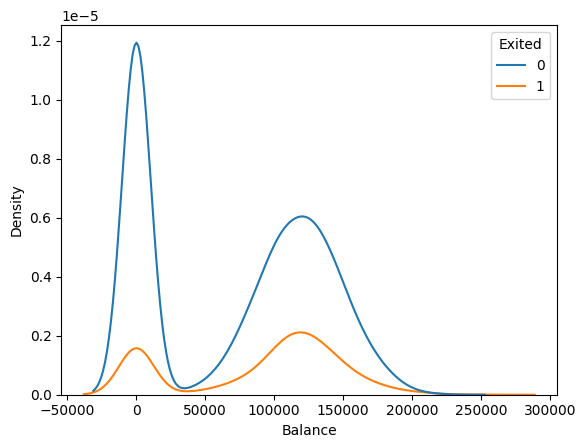

In [95]:
sns.kdeplot(data = df, x = "Balance", hue = "Exited")

In [97]:
df.columns

Index(['Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')

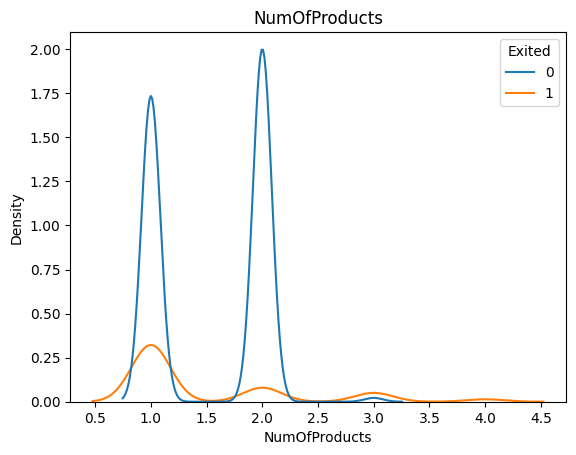

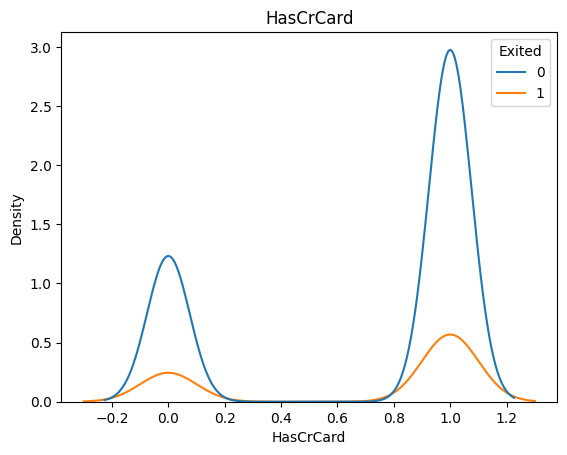

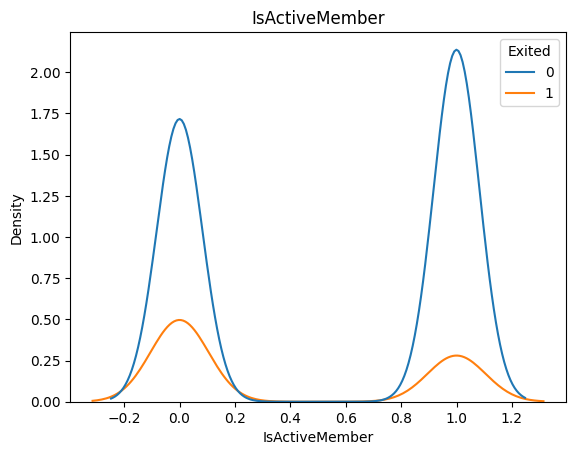

In [103]:
columns = ['NumOfProducts', 'HasCrCard', 'IsActiveMember']

for col in columns:
    sns.kdeplot(df, x = col, hue = "Exited")
    plt.title(col)
    plt.show()

none of the last diagrams are normal in nature excluding the ordinal encoded ones

plan of attack
\n
need to add scalers for everything
need to use one hot encoders for geography, surname and gender
can use ordinal encoding for surname
need to transform using power transformers for normalized behaviour 

does not seem to have a lot of noise and thus clipping can be omitted